In [57]:
#Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 



In [58]:
#Load Datasets
clients = pd.read_csv("clients.csv")
properties = pd.read_csv("properties.csv")

In [59]:
#Check Dataset Dimension

print("Client Dataset:", clients.shape)
print("Properties Dataset:", properties.shape)


Client Dataset: (2000, 12)
Properties Dataset: (10000, 9)


In [60]:
#Display Column Names
print("\nClient Columns:")
print(clients.columns.tolist())

print("\nProperty Columns:")
print(properties.columns.tolist())


Client Columns:
['client_id', 'client_type', 'first_name', 'last_name', 'date_of_birth', 'gender', 'country', 'region', 'acquisition_purpose', 'satisfaction_score', 'loan_applied', 'referral_channel']

Property Columns:
['listing_id', 'tower_number', 'transaction_date', 'unit_category', 'unit_number', 'floor_area_sqft', 'sale_price', 'listing_status', 'client_ref']


In [61]:
clients.head()

,client_id,client_type,first_name,last_name,date_of_birth,gender,country,region,acquisition_purpose,satisfaction_score,loan_applied,referral_channel
0,C0001,Individual,Kareem,Liu,05-11-1968,F,USA,California,Home,4,Yes,Website
1,C0002,Individual,Trystan,Oconnor,11/26/1962,M,USA,California,Home,1,No,Website
2,C0003,Individual,Kale,Gay,04-07-1959,M,USA,California,Home,4,Yes,Agency
3,C0004,Individual,Russell,Gross,11/25/1959,M,USA,California,Home,5,No,Website
4,C0005,Company,Marleez,Co,2/28/1976,M,USA,California,Investment,5,No,Website


In [62]:
properties.head()

,listing_id,tower_number,transaction_date,unit_category,unit_number,floor_area_sqft,sale_price,listing_status,client_ref
0,1012,1,01-01-2024,Apartment,12,1160.36,"$300,385.62",Sold,C0027
1,1015,1,01-01-2024,Apartment,15,782.25,"$208,930.81",Sold,C0097
2,1021,1,01-01-2024,Apartment,21,756.21,"$218,585.92",Sold,C0113
3,1030,1,01-01-2024,Apartment,30,743.09,"$246,172.68",Sold,C0141
4,2016,2,01-01-2024,Apartment,16,701.66,"$212,265.67",Sold,C0146


In [63]:
print("Clients Data Quality")
display(pd.DataFrame({
    "Data Type":clients.dtypes.astype(str),
    "Missing Values": clients.isnull().sum(),
    "Unique Values": clients.nunique()
}))
print("Properties Data Quality")
display(pd.DataFrame({
    "Data Type": properties.dtypes.astype(str),
    "Missing Values": properties.isnull().sum(),
    "Unique Values": properties.nunique()
}))

Clients Data Quality


,Data Type,Missing Values,Unique Values
client_id,object,0,2000
client_type,object,0,2
first_name,object,0,337
last_name,object,0,224
date_of_birth,object,0,1889
gender,object,0,2
country,object,0,10
region,object,0,57
acquisition_purpose,object,0,2
satisfaction_score,int64,0,5


Properties Data Quality


,Data Type,Missing Values,Unique Values
listing_id,int64,0,10000
tower_number,int64,0,20
transaction_date,object,0,24
unit_category,object,0,2
unit_number,int64,0,70
floor_area_sqft,float64,0,1208
sale_price,object,0,9998
listing_status,object,0,2
client_ref,object,2695,2000


In [64]:
#Check Duplicate Records
print("Clients Dataset")
print("Duplicate Rows:", clients.duplicated().sum())
print("Duplicate Client ID:", clients["client_id"].duplicated().sum())

print("\nProperties Dataset")
print("Duplicate Rows:", properties.duplicated().sum())
print("Duplicate listing ID:", properties["listing_id"].duplicated().sum())

Clients Dataset
Duplicate Rows: 0
Duplicate Client ID: 0

Properties Dataset
Duplicate Rows: 0
Duplicate listing ID: 0


In [65]:
#Check Listing Status Counts
print("Listing Status Distribution:")
print(properties["listing_status"].value_counts(dropna=False))

print("\nMissing Client References by Listing Status:")
print(properties.groupby("listing_status")["client_ref"]
      .apply(lambda x: x.isnull().sum()))

Listing Status Distribution:
listing_status
Sold         7305
Available    2695
Name: count, dtype: int64

Missing Client References by Listing Status:
listing_status
Available    2695
Sold            0
Name: client_ref, dtype: int64


In [66]:
#Get all valid client IDs
valid_client_ids = set(clients["client_id"].astype(str).str.strip())

#Get non-missing property client references
property_client_refs = properties["client_ref"].dropna().astype(str).str.strip()

#Identify references that do not match any client ID
unmatched_refs = property_client_refs[property_client_refs.isin(valid_client_ids)]

print("Total Property Records:", len(properties))
print("Missing Client References:", properties["client_ref"].isnull().sum())
print("Non-Missing CLient References:", properties["client_ref"].notnull().sum())
print("Unmatched Client References:", len(unmatched_refs))
    



Total Property Records: 10000
Missing Client References: 2695
Non-Missing CLient References: 7305
Unmatched Client References: 7305


In [67]:
#Inspect Client IDs
print("Sample Client IDs:")
print(clients["client_id"].head(10).tolist())

#Inspect Property Client Refs
print("\nSample Property Client References:")
print(properties["client_ref"].dropna().head(10).tolist())

#Check whitespace and formatting 
print("\nClient IDs after string conversion:")
print(clients["client_id"].astype(str).str.strip().head(5).tolist())

print("\nProperty references after string conversion:")
print(properties["client_ref"].dropna().astype(str).str.strip().head(5).tolist())


Sample Client IDs:
['C0001', 'C0002', 'C0003', 'C0004', 'C0005', 'C0006', 'C0007', 'C0008', 'C0009', 'C0010']

Sample Property Client References:
['C0027', 'C0097', 'C0113', 'C0141', 'C0146', 'C0023', 'C0040', 'C0007', 'C0082', 'C0038']

Client IDs after string conversion:
['C0001', 'C0002', 'C0003', 'C0004', 'C0005']

Property references after string conversion:
['C0027', 'C0097', 'C0113', 'C0141', 'C0146']


In [68]:
#Normalize IDs for comparison
client_ids = clients["client_id"].astype("string").str.strip()
property_refs = properties["client_ref"].astype("string").str.strip()

#Compare unique IDs
client_id_set = set(client_ids.dropna())
property_ref_set = set(property_refs.dropna())

matched_ids = property_ref_set.intersection(client_id_set)
unmatched_ids = property_ref_set.difference(client_id_set)

print("Unique client IDs:", len(client_id_set))
print("Unique non-missing property references:", len(property_ref_set))
print("Matching unique IDs:", len(matched_ids))
print("Unmatched unique IDs:", len(unmatched_ids))

print("\nSample matching IDs:")
print(list(sorted(matched_ids))[:10])

print("\nSample unmatched IDs:")
print(list(sorted(unmatched_ids))[:10])


Unique client IDs: 2000
Unique non-missing property references: 2000
Matching unique IDs: 2000
Unmatched unique IDs: 0

Sample matching IDs:
['C0001', 'C0002', 'C0003', 'C0004', 'C0005', 'C0006', 'C0007', 'C0008', 'C0009', 'C0010']

Sample unmatched IDs:
[]


In [69]:
#Check the number of records for each listing status
print("Listing Status Counts:")
print(properties["listing_status"].value_counts(dropna=False))

#Check missing client references for each status 
print("\nMissing Client References by Listing Status:")
print(properties.groupby("listing_status")["client_ref"]
      .apply(lambda x: x.isnull().sum())
     )

#Calculate missing reference percentages by status
print("\nMissing Reference Percentage by Status:")
print(properties.groupby("listing_status")["client_ref"]
      .apply(lambda x: round(x.isnull().mean()*100,2)))


Listing Status Counts:
listing_status
Sold         7305
Available    2695
Name: count, dtype: int64

Missing Client References by Listing Status:
listing_status
Available    2695
Sold            0
Name: client_ref, dtype: int64

Missing Reference Percentage by Status:
listing_status
Available    100.0
Sold           0.0
Name: client_ref, dtype: float64


In [70]:
#Inspect transaction dates
print("Sample transaction dates:")
print(properties["transaction_date"].head(10).tolist())

print("\nUnique transaction dates:")
print(properties["transaction_date"].nunique())

#Inspect sales prices
print("\nSample sale prices:")
print(properties["sale_price"].head(10).tolist())

print("\nSale price data type:")
print(properties["sale_price"].dtype)

#Check listing status and price together
print("\nSales prices by listing status:")
display(
    properties.groupby("listing_status")["sale_price"]
    .agg(["count", "nunique"])
)

Sample transaction dates:
['01-01-2024', '01-01-2024', '01-01-2024', '01-01-2024', '01-01-2024', '01-01-2024', '01-01-2024', '01-01-2024', '01-01-2024', '01-01-2024']

Unique transaction dates:
24

Sample sale prices:
['$300,385.62', '$208,930.81', '$218,585.92', '$246,172.68', '$212,265.67', '$275,394.25', '$310,223.29', '$356,506.37', '$212,520.83', '$407,214.29']

Sale price data type:
object

Sales prices by listing status:


,count,nunique
listing_status,,
Available,2695,2695
Sold,7305,7303


In [71]:
#Create a working copy 
properties_clean = properties.copy()

#Convert transaction date to datetime 
properties_clean["transaction_date_clean"] = pd.to_datetime(
    properties_clean["transaction_date"],
    format="%d-%m-%Y",
    errors="coerce"
)

#Remove currency symbols and commas from sale price
properties_clean["sale_price_clean"] = pd.to_numeric(
    properties_clean["sale_price"]
    .astype("string")
    .str.replace(r"[$,]", "", regex=True)
    .str.strip(),
    errors="coerce"
)

#Check conversion results 
print("Original date data type:",
      properties_clean["transaction_date"].dtype)
print("Cleaned date data type:",
      properties_clean["transaction_date_clean"].dtype)
print("\nInvalid dates:",
      properties_clean["transaction_date_clean"].isnull().sum())
print("Invalid sale prices:",
      properties_clean["sale_price_clean"].isnull().sum())
print("\nCleaned Sample:")
display(
    properties_clean[
        ["transaction_date", "transaction_date_clean", "sale_price", "sale_price_clean", "listing_status"]
        ].head(10)
)
      


Original date data type: object
Cleaned date data type: datetime64[ns]

Invalid dates: 0
Invalid sale prices: 0

Cleaned Sample:


,transaction_date,transaction_date_clean,sale_price,sale_price_clean,listing_status
0,01-01-2024,2024-01-01,"$300,385.62",300385.62,Sold
1,01-01-2024,2024-01-01,"$208,930.81",208930.81,Sold
2,01-01-2024,2024-01-01,"$218,585.92",218585.92,Sold
3,01-01-2024,2024-01-01,"$246,172.68",246172.68,Sold
4,01-01-2024,2024-01-01,"$212,265.67",212265.67,Sold
5,01-01-2024,2024-01-01,"$275,394.25",275394.25,Sold
6,01-01-2024,2024-01-01,"$310,223.29",310223.29,Sold
7,01-01-2024,2024-01-01,"$356,506.37",356506.37,Sold
8,01-01-2024,2024-01-01,"$212,520.83",212520.83,Sold
9,01-01-2024,2024-01-01,"$407,214.29",407214.29,Sold


In [72]:
#Check date range 
print("Earliest transaction date:",
      properties_clean["transaction_date_clean"].min())
print("Latest transaction date:",
      properties_clean["transaction_date_clean"].max())

#Check sale price statistics
print("\nSale Price Statistics:")
display(properties_clean["sale_price_clean"].describe())

#Check floor area statistics
print("\nFloor Area Statistics:")
display(properties_clean["floor_area_sqft"].describe())

#Check invalid or suspicious numeric values
print("\nNon_Positive sale prices:",
      (properties_clean["sale_price_clean"] <= 0).sum())
print("Non-Positive floor areas:",
      (properties_clean["floor_area_sqft"] <= 0).sum())

#Check missing values in cleaned columns
print("\nMissing cleaned dates:",
      properties_clean["transaction_date_clean"].isnull().sum())
print("Missing cleaned sale prices:",
      properties_clean["sale_price_clean"].isnull().sum())

Earliest transaction date: 2024-01-01 00:00:00
Latest transaction date: 2025-01-12 00:00:00

Sale Price Statistics:


count          10000.0
mean     344374.678683
std      131563.099417
min            97402.8
25%        232173.6425
50%         330680.845
75%         448852.575
max          736652.27
Name: sale_price_clean, dtype: Float64


Floor Area Statistics:


count    10000.000000
mean      1139.941412
std        418.373967
min        410.710000
25%        782.200000
50%       1110.880000
75%       1499.000000
max       1957.160000
Name: floor_area_sqft, dtype: float64


Non_Positive sale prices: 0
Non-Positive floor areas: 0

Missing cleaned dates: 0
Missing cleaned sale prices: 0


In [73]:
#Inspect categorical columns in clients
client_categorical_cols = [
    "client_type",
    "gender",
    "country",
    "region",
    "acquisition_purpose",
    "loan_applied",
    "referral_channel"
]
for col in client_categorical_cols:
    print(f"\n{col}:")
    print(clients[col].value_counts(dropna=False))

    #Inspect property categories
    property_categorical_cols = [
    "unit_category",
    "listing_status"
    ]
    for col in property_categorical_cols:
        print(f"\n{col}:")
        print(properties_clean[col].value_counts(dropna=False))


client_type:
client_type
Individual    1897
Company        103
Name: count, dtype: int64

unit_category:
unit_category
Apartment    8547
Office       1453
Name: count, dtype: int64

listing_status:
listing_status
Sold         7305
Available    2695
Name: count, dtype: int64

gender:
gender
M    1012
F     988
Name: count, dtype: int64

unit_category:
unit_category
Apartment    8547
Office       1453
Name: count, dtype: int64

listing_status:
listing_status
Sold         7305
Available    2695
Name: count, dtype: int64

country:
country
USA          1538
UK             95
Canada         85
Germany        56
France         53
Belgium        43
Mexico         40
Australia      39
Russia         36
Denmark        15
Name: count, dtype: int64

unit_category:
unit_category
Apartment    8547
Office       1453
Name: count, dtype: int64

listing_status:
listing_status
Sold         7305
Available    2695
Name: count, dtype: int64

region:
region
California                633
Nevada              

In [74]:

# Create cleaned copies
clients_clean = clients.copy()
properties_clean = properties_clean.copy()

# Standardize whitespace in client categorical columns
client_categorical_cols = [
    "client_type",
    "gender",
    "country",
    "region",
    "acquisition_purpose",
    "loan_applied",
    "referral_channel"
]

for col in client_categorical_cols:
    clients_clean[col] = (
        clients_clean[col]
        .astype("string")
        .str.strip()
    )

# Standardize whitespace in property categorical columns
property_categorical_cols = [
    "unit_category",
    "listing_status"
]

for col in property_categorical_cols:
    properties_clean[col] = (
        properties_clean[col]
        .astype("string")
        .str.strip()
    )

# Verify category values after cleaning
for col in client_categorical_cols:
    print(f"{col}: {sorted(clients_clean[col].dropna().unique().tolist())}")

for col in property_categorical_cols:
    print(f"{col}: {sorted(properties_clean[col].dropna().unique().tolist())}")


client_type: ['Company', 'Individual']
gender: ['F', 'M']
country: ['Australia', 'Belgium', 'Canada', 'Denmark', 'France', 'Germany', 'Mexico', 'Russia', 'UK', 'USA']
region: ['Alberta', 'Arizona', 'Baja California', 'Bavaria', 'Berlin', 'British Columbia', 'Brittany', 'Brussels', 'California', 'Capital Region', 'Central Denmark', 'Colorado', 'England', 'Flanders', 'Florida', 'Georgia', 'Hamburg', 'Hesse', 'Ile-de-France', 'Jalisco', 'Kansas', 'Krasnodar Krai', 'Manitoba', 'Mexico City', 'Moscow Oblast', 'Nevada', 'New South Wales', 'New York', 'Normandy', 'North Denmark', 'North Rhine-Westphalia', 'Northern Ireland', 'Novosibirsk', 'Nuevo Leon', 'Occitanie', 'Ohio', 'Ontario', 'Oregon', 'Provence', 'Puebla', 'Quebec', 'Queensland', 'Saint Petersburg', 'Scotland', 'South Australia', 'Southern Denmark', 'Tatarstan', 'Texas', 'Utah', 'Victoria', 'Virginia', 'Wales', 'Wallonia', 'Washington', 'Western Australia', 'Wyoming', 'Zealand']
acquisition_purpose: ['Home', 'Investment']
loan_appli

In [75]:
#Final validation of cleaned datasets

print("Clients Cleaned Dataset")
print("Shape:", clients_clean.shape)
print("Duplicate Rows:", clients_clean.duplicated().sum())
print("Duplicate Client IDs:",
      clients_clean["client_id"].duplicated().sum())
print("Total missing values:",
      clients_clean.isnull().sum())

print("\nProperties Cleaned Dataset")
print("Shape:", properties_clean.shape)
print("Duplicate Rows:", properties_clean.duplicated().sum())
print("Duplicate Listing IDs:",
      properties_clean["listing_id"].duplicated().sum())
print("Total missing values:",
      properties_clean.isnull().sum())

# Validate cleaned date and price columns
print("\nCLEANED DATE AND PRICE VALIDATION")
print("Invalid dates:",
      properties_clean["transaction_date_clean"].isna().sum())
print("Invalid prices:",
      properties_clean["sale_price_clean"].isna().sum())

# Check property-client ID matching
client_ids = set(
    clients_clean["client_id"].astype("string").str.strip().dropna()
)

property_refs = set(
    properties_clean["client_ref"].astype("string").str.strip().dropna()
)

print("Unmatched client references:",
      len(property_refs - client_ids))


Clients Cleaned Dataset
Shape: (2000, 12)
Duplicate Rows: 0
Duplicate Client IDs: 0
Total missing values: client_id              0
client_type            0
first_name             0
last_name              0
date_of_birth          0
gender                 0
country                0
region                 0
acquisition_purpose    0
satisfaction_score     0
loan_applied           0
referral_channel       0
dtype: int64

Properties Cleaned Dataset
Shape: (10000, 11)
Duplicate Rows: 0
Duplicate Listing IDs: 0
Total missing values: listing_id                   0
tower_number                 0
transaction_date             0
unit_category                0
unit_number                  0
floor_area_sqft              0
sale_price                   0
listing_status               0
client_ref                2695
transaction_date_clean       0
sale_price_clean             0
dtype: int64

CLEANED DATE AND PRICE VALIDATION
Invalid dates: 0
Invalid prices: 0
Unmatched client references: 0


In [76]:

from pathlib import Path

print("Current notebook directory:")
print(Path.cwd())


Current notebook directory:
/home/9fca1d4d-6d6e-4aea-a19c-bd45c4f5eaba


In [77]:

from pathlib import Path

save_folder = Path.cwd()

clients_clean.to_csv(save_folder / "clients_clean.csv", index=False)
properties_clean.to_csv(save_folder / "properties_clean.csv", index=False)

print("Clients CSV saved:", (save_folder / "clients_clean.csv").exists())
print("Properties CSV saved:", (save_folder / "properties_clean.csv").exists())
print("Save location:", save_folder)


Clients CSV saved: True
Properties CSV saved: True
Save location: /home/9fca1d4d-6d6e-4aea-a19c-bd45c4f5eaba


Buyer Counts by Client Type:
client_type
Individual    1897
Company        103
Name: count, dtype: Int64


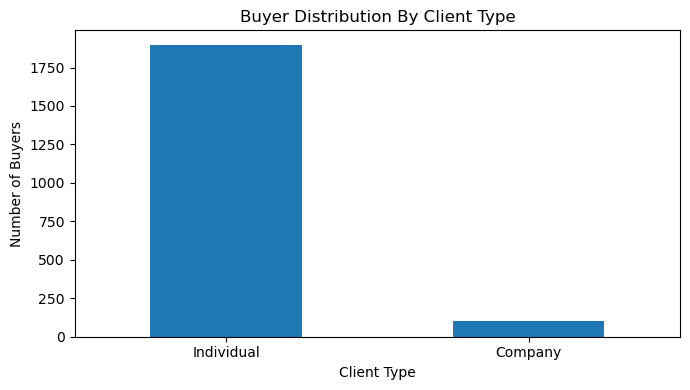

In [78]:
#Buyer Counts by Client Type
client_type_counts = clients_clean["client_type"].value_counts()
print("Buyer Counts by Client Type:")
print(client_type_counts)

#Plot Buyer Distribution 
client_type_counts.plot(
    kind='bar',
    figsize=(7,4),
    title="Buyer Distribution By Client Type",
    xlabel="Client Type",
    ylabel="Number of Buyers",
    rot=0
)
plt.tight_layout()
plt.show()

Buyer Counts by Acquisition Purpose
acquisition_purpose
Home          1385
Investment     615
Name: count, dtype: Int64

Buyer Percentages:
acquisition_purpose
Home          69.25
Investment    30.75
Name: proportion, dtype: Float64


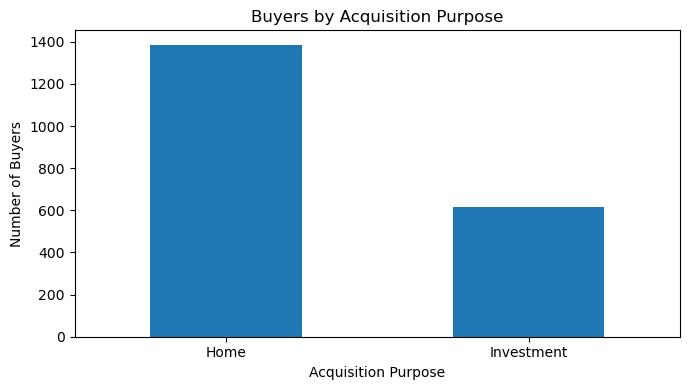

In [79]:
#Count Buyers by Acquisition Purpose
purpose_counts = clients_clean["acquisition_purpose"].value_counts()
print("Buyer Counts by Acquisition Purpose")
print(purpose_counts)

#Calculate Percentages
purpose_percentages = (
    clients_clean["acquisition_purpose"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)
print("\nBuyer Percentages:")
print(purpose_percentages)

#Plot acquisition purpose
purpose_counts.plot(
    kind='bar',
    figsize=(7,4),
    title="Buyers by Acquisition Purpose",
    xlabel="Acquisition Purpose",
    ylabel="Number of Buyers",
    rot=0
)
plt.tight_layout()
plt.show()


Buyer Purpose vs Loan Application:


loan_applied,No,Yes
acquisition_purpose,,
Home,883,502
Investment,381,234



Loan Application Percentage Within Each Purpose:


loan_applied,No,Yes
acquisition_purpose,,
Home,63.75,36.25
Investment,61.95,38.05


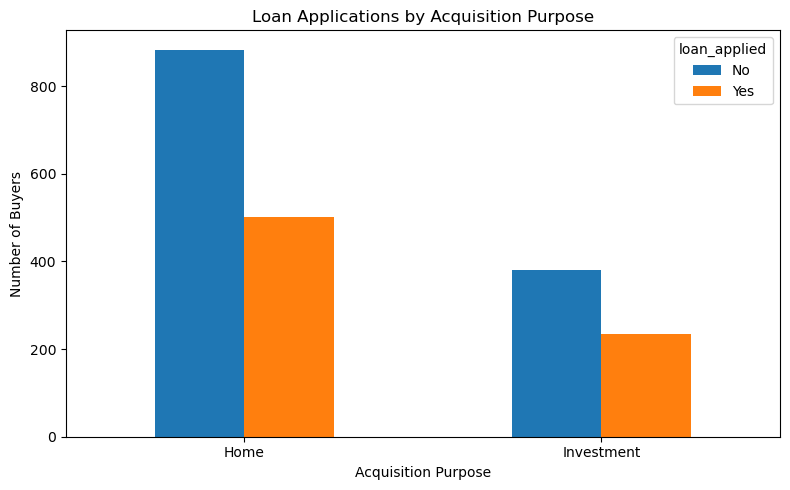

In [80]:
#Acquisition Purpose vs Loan Application
loan_purpose = pd.crosstab(
    clients_clean["acquisition_purpose"],
    clients_clean["loan_applied"]
)
print("Buyer Purpose vs Loan Application:")
display(loan_purpose)
#Calculate Loan Application Percentages within each purpose
loan_purpose_pct = pd.crosstab(
    clients_clean["acquisition_purpose"],
    clients_clean["loan_applied"],
    normalize="index"
).mul(100).round(2)

print("\nLoan Application Percentage Within Each Purpose:")
display(loan_purpose_pct)

#Plot the Counts
loan_purpose.plot(
    kind='bar',
    figsize=(8,5),
    title="Loan Applications by Acquisition Purpose",
    xlabel="Acquisition Purpose",
    ylabel="Number of Buyers",
    rot=0
)
plt.tight_layout()
plt.show()

Overall Satisfaction Score Distribution
satisfaction_score
1    395
2    379
3    404
4    417
5    405
Name: count, dtype: int64

Satisfaction by Acquisition Purpose:


,count,mean,median
acquisition_purpose,,,
Home,1385,3.02,3.0
Investment,615,3.04,3.0


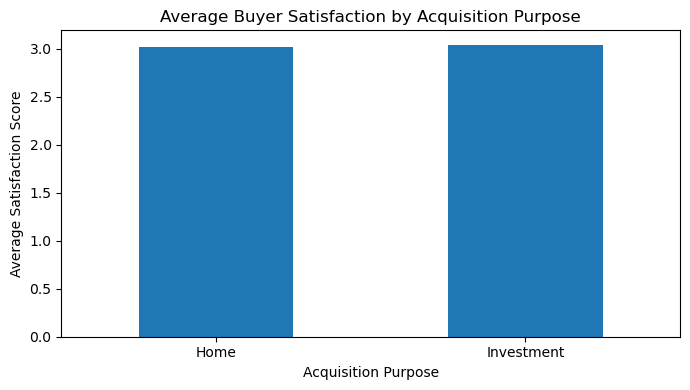

In [81]:
#Satisfaction score distribution
print("Overall Satisfaction Score Distribution")
print(clients_clean["satisfaction_score"].value_counts().sort_index())

#Average satisfaction by Acquisition Purpose
satisfaction_by_purpose = (
    clients_clean.groupby("acquisition_purpose")["satisfaction_score"]
    .agg(["count", "mean", "median"])
    .round(2)
)
print("\nSatisfaction by Acquisition Purpose:")
display(satisfaction_by_purpose)

#Plot average satisfaction
satisfaction_by_purpose["mean"].plot(
    kind='bar',
    figsize=(7,4),
    title="Average Buyer Satisfaction by Acquisition Purpose",
    xlabel="Acquisition Purpose",
    ylabel="Average Satisfaction Score",
    rot=0
)
plt.tight_layout()
plt.show()




In [82]:

# Inspect the original date-of-birth format
print(clients_clean["date_of_birth"].head(10).tolist())

# Parse dates using the format found in your data
clients_clean["dob_clean"] = pd.to_datetime(
    clients_clean["date_of_birth"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Check conversion results
print("\nConverted dates:")
display(
    clients_clean[
        ["date_of_birth", "dob_clean"]
    ].head(10)
)

print("\nInvalid dates:", clients_clean["dob_clean"].isna().sum())


['05-11-1968', '11/26/1962', '04-07-1959', '11/25/1959', '2/28/1976', '03-06-1957', '5/24/1947', '10/17/1969', '10-05-1975', '6/17/1966']

Converted dates:


,date_of_birth,dob_clean
0,05-11-1968,NaT
1,11/26/1962,1962-11-26
2,04-07-1959,NaT
3,11/25/1959,1959-11-25
4,2/28/1976,1976-02-28
5,03-06-1957,NaT
6,5/24/1947,1947-05-24
7,10/17/1969,1969-10-17
8,10-05-1975,NaT
9,6/17/1966,1966-06-17



Invalid dates: 855


Buyer Age Statistics:


count    1145.00
mean       56.50
std        17.44
min        25.00
25%        42.00
50%        57.00
75%        71.00
max        95.00
Name: age, dtype: float64


Age by Acquisition Purpose:


,count,mean,median,min,max
acquisition_purpose,,,,,
Home,797,56.85,58.0,25.0,95.0
Investment,348,55.69,55.0,26.0,94.0


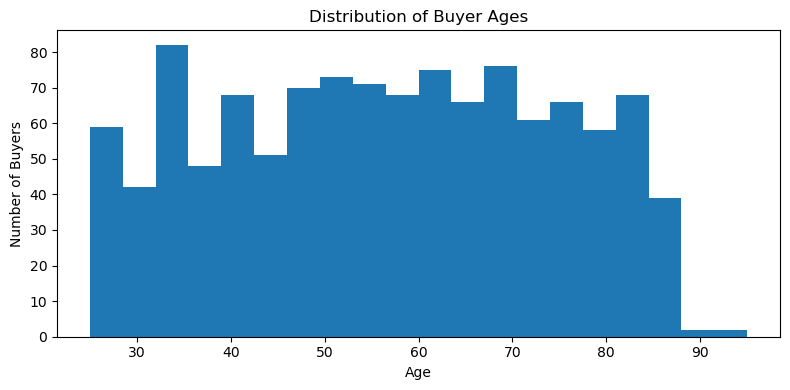

In [83]:

# Fixed reference date for consistent project analysis
reference_date = pd.Timestamp("2026-10-17")

# Calculate age accurately, accounting for birthdays
birth_dates = clients_clean["dob_clean"]

clients_clean["age"] = (
    reference_date.year
    - birth_dates.dt.year
    - (
        (birth_dates.dt.month > reference_date.month)
        | (
            (birth_dates.dt.month == reference_date.month)
            & (birth_dates.dt.day > reference_date.day)
        )
    ).astype(int)
)

print("Buyer Age Statistics:")
display(clients_clean["age"].describe().round(2))

print("\nAge by Acquisition Purpose:")
display(
    clients_clean.groupby("acquisition_purpose")["age"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

# Plot age distribution
clients_clean["age"].plot(
    kind="hist",
    bins=20,
    figsize=(8, 4),
    title="Distribution of Buyer Ages",
    xlabel="Age",
    ylabel="Number of Buyers"
)

plt.tight_layout()
plt.show()


In [84]:

# Inspect date formats and failed conversions
dob = clients_clean["date_of_birth"].astype("string").str.strip()

print("Date separator counts:")
display(
    dob.str.extract(r"([-/.])", expand=False)
    .value_counts(dropna=False)
)

# Show examples that failed the previous conversion
invalid_dob = dob[clients_clean["dob_clean"].isna()]

print("\nExamples of dates that failed:")
display(invalid_dob.head(20))

print("\nTotal invalid dates:", invalid_dob.shape[0])


Date separator counts:


date_of_birth
/    1145
-     855
Name: count, dtype: Int64


Examples of dates that failed:


0     05-11-1968
2     04-07-1959
5     03-06-1957
8     10-05-1975
12    08-10-1962
13    07-10-1980
15    09-03-1939
16    01-08-1977
17    02-07-1967
18    09-09-1957
20    06-09-1938
22    12-06-1958
23    11-05-1963
26    09-08-1968
31    08-11-1966
34    05-12-1965
35    09-01-1973
41    08-12-1975
42    04-04-1965
44    10-12-1968
Name: date_of_birth, dtype: string


Total invalid dates: 855


In [85]:

dob = clients_clean["date_of_birth"].astype("string").str.strip()

# Candidate 1: Month-Day-Year for hyphens
dob_mdy = pd.to_datetime(
    dob.str.replace("-", "/", regex=False),
    format="%m/%d/%Y",
    errors="coerce"
)

# Candidate 2: Day-Month-Year for hyphens
dob_dmy = pd.to_datetime(
    dob.str.replace("-", "/", regex=False),
    format="%d/%m/%Y",
    errors="coerce"
)

# Keep the already-converted slash dates in both candidates
slash_dates = dob.str.contains("/", na=False)
dob_mdy.loc[slash_dates] = pd.to_datetime(
    dob.loc[slash_dates],
    format="%m/%d/%Y",
    errors="coerce"
)
dob_dmy.loc[slash_dates] = dob_mdy.loc[slash_dates]

reference_date = pd.Timestamp("2026-10-17")

def calculate_age(birth_dates):
    age = (
        reference_date.year - birth_dates.dt.year
        - (
            (birth_dates.dt.month > reference_date.month)
            | (
                (birth_dates.dt.month == reference_date.month)
                & (birth_dates.dt.day > reference_date.day)
            )
        ).astype("Int64")
    )
    return age

age_mdy = calculate_age(dob_mdy)
age_dmy = calculate_age(dob_dmy)

print("Month-Day-Year interpretation:")
print("Valid dates:", dob_mdy.notna().sum())
display(age_mdy.describe().round(2))

print("\nDay-Month-Year interpretation:")
print("Valid dates:", dob_dmy.notna().sum())
display(age_dmy.describe().round(2))

print("\nSample comparison:")
display(pd.DataFrame({
    "original": dob,
    "MDY_date": dob_mdy,
    "MDY_age": age_mdy,
    "DMY_date": dob_dmy,
    "DMY_age": age_dmy
}).loc[~slash_dates].head(15))


Month-Day-Year interpretation:
Valid dates: 2000


count    2000.0
mean       55.9
std       17.36
min        25.0
25%        41.0
50%        56.0
75%        70.0
max        95.0
Name: date_of_birth, dtype: Float64


Day-Month-Year interpretation:
Valid dates: 2000


count    2000.0
mean      55.91
std       17.35
min        25.0
25%        41.0
50%        56.0
75%        70.0
max        95.0
Name: date_of_birth, dtype: Float64


Sample comparison:


,original,MDY_date,MDY_age,DMY_date,DMY_age
0,05-11-1968,1968-05-11,58,1968-11-05,57
2,04-07-1959,1959-04-07,67,1959-07-04,67
5,03-06-1957,1957-03-06,69,1957-06-03,69
8,10-05-1975,1975-10-05,51,1975-05-10,51
12,08-10-1962,1962-08-10,64,1962-10-08,64
13,07-10-1980,1980-07-10,46,1980-10-07,46
15,09-03-1939,1939-09-03,87,1939-03-09,87
16,01-08-1977,1977-01-08,49,1977-08-01,49
17,02-07-1967,1967-02-07,59,1967-07-02,59
18,09-09-1957,1957-09-09,69,1957-09-09,69


In [86]:

# Provisional assumption: all DOB values use Month-Day-Year
clients_clean["dob_clean"] = dob_mdy

# Calculate age using the fixed project reference date
clients_clean["age"] = calculate_age(clients_clean["dob_clean"])

print("Missing ages:", clients_clean["age"].isna().sum())
print("Age range:", clients_clean["age"].min(), "to", clients_clean["age"].max())
print("Average age:", round(clients_clean["age"].mean(), 2))

# Save the assumption for your project documentation
print(
    "\nData quality note: DOB values were parsed using "
    "Month-Day-Year format. Hyphen-separated dates require "
    "confirmation from the dataset source."
)


Missing ages: 0
Age range: 25 to 95
Average age: 55.9

Data quality note: DOB values were parsed using Month-Day-Year format. Hyphen-separated dates require confirmation from the dataset source.


Buyer Counts by Country:


country
USA          1538
UK             95
Canada         85
Germany        56
France         53
Belgium        43
Mexico         40
Australia      39
Russia         36
Denmark        15
Name: count, dtype: Int64


Buyer Percentages by Country:


country
USA          76.9
UK           4.75
Canada       4.25
Germany       2.8
France       2.65
Belgium      2.15
Mexico        2.0
Australia    1.95
Russia        1.8
Denmark      0.75
Name: proportion, dtype: Float64

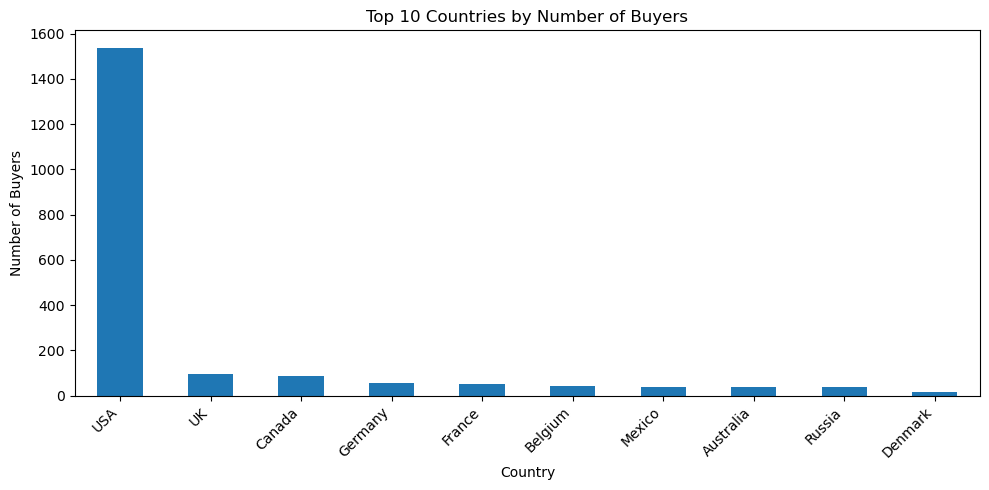

In [87]:
#Count Buyers by Country
country_counts = clients_clean["country"].value_counts()
print("Buyer Counts by Country:")
display(country_counts)

#Percentage Distribution 
country_percentages = (
    clients_clean["country"].value_counts(normalize=True) * 100
).round(2)
print("\nBuyer Percentages by Country:")
display(country_percentages)

#Visualize top 10 countries
country_counts.head(10).plot(
    kind='bar',
    figsize=(10,5),
    title="Top 10 Countries by Number of Buyers",
    xlabel="Country",
    ylabel="Number of Buyers"
)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Buyer Counts by Country and Acquisition Purpose:


acquisition_purpose,Home,Investment
country,,
Australia,31,8
Belgium,27,16
Canada,52,33
Denmark,11,4
France,37,16
Germany,40,16
Mexico,25,15
Russia,28,8
UK,66,29



Acquisition Purpose Percentage Within Each Country:


acquisition_purpose,Home,Investment
country,,
Australia,79.49,20.51
Belgium,62.79,37.21
Canada,61.18,38.82
Denmark,73.33,26.67
France,69.81,30.19
Germany,71.43,28.57
Mexico,62.50,37.50
Russia,77.78,22.22
UK,69.47,30.53


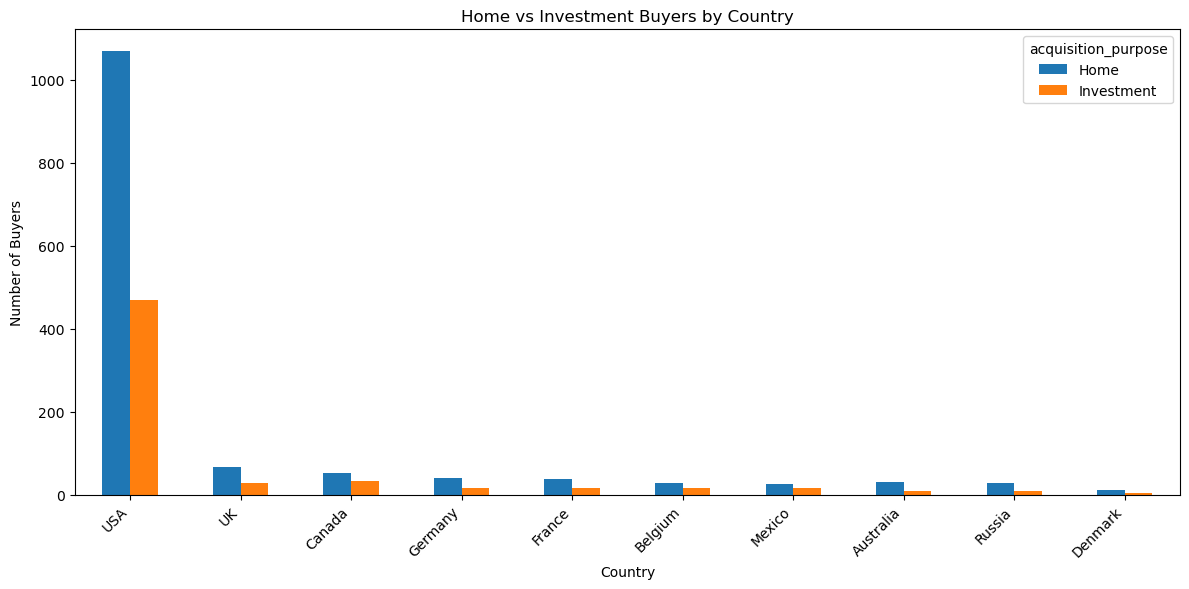

In [88]:

# Count Home and Investment buyers by country
country_purpose_counts = pd.crosstab(
    clients_clean["country"],
    clients_clean["acquisition_purpose"]
)

print("Buyer Counts by Country and Acquisition Purpose:")
display(country_purpose_counts)

# Calculate percentage within each country
country_purpose_percent = pd.crosstab(
    clients_clean["country"],
    clients_clean["acquisition_purpose"],
    normalize="index"
).mul(100).round(2)

print("\nAcquisition Purpose Percentage Within Each Country:")
display(country_purpose_percent)

# Plot the top 10 countries, ordered by buyer count
top_countries = country_counts.head(10).index

country_purpose_counts.loc[top_countries].plot(
    kind="bar",
    figsize=(12, 6),
    title="Home vs Investment Buyers by Country",
    xlabel="Country",
    ylabel="Number of Buyers"
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


Top 15 Regions by Buyer Count:


region
California    633
Nevada        143
Colorado      118
Arizona       108
Oregon         96
Utah           87
Washington     73
Virginia       65
Texas          56
Florida        50
New York       49
Georgia        34
England        29
Alberta        27
Scotland       25
Name: count, dtype: Int64


Buyer Counts by Region and Purpose:


acquisition_purpose,Home,Investment
region,,
California,443,190
Nevada,92,51
Colorado,80,38
Arizona,72,36
Oregon,58,38
Utah,60,27
Washington,53,20
Virginia,45,20
Texas,38,18



Purpose Percentages Within Each Region:


acquisition_purpose,Home,Investment
region,,
California,69.98,30.02
Nevada,64.34,35.66
Colorado,67.80,32.20
Arizona,66.67,33.33
Oregon,60.42,39.58
Utah,68.97,31.03
Washington,72.60,27.40
Virginia,69.23,30.77
Texas,67.86,32.14


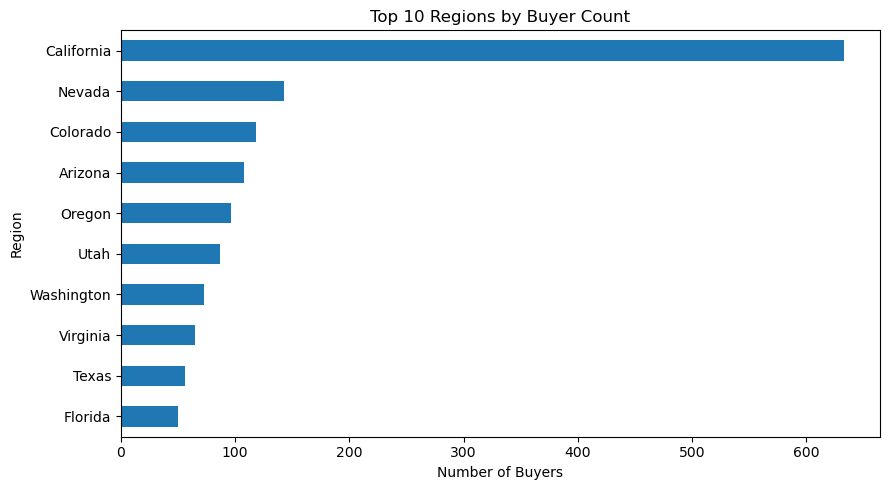

In [89]:

# Count buyers by region
region_counts = clients_clean["region"].value_counts()

print("Top 15 Regions by Buyer Count:")
display(region_counts.head(15))

# Select the 15 regions with the most buyers
top_regions = region_counts.head(15).index

# Count Home and Investment buyers in these regions
region_purpose_counts = pd.crosstab(
    clients_clean["region"],
    clients_clean["acquisition_purpose"]
).loc[top_regions]

print("\nBuyer Counts by Region and Purpose:")
display(region_purpose_counts)

# Calculate purpose percentages within each region
region_purpose_percent = pd.crosstab(
    clients_clean["region"],
    clients_clean["acquisition_purpose"],
    normalize="index"
).mul(100).round(2).loc[top_regions]

print("\nPurpose Percentages Within Each Region:")
display(region_purpose_percent)

# Plot top 10 regions by buyer count
region_counts.head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Top 10 Regions by Buyer Count",
    xlabel="Number of Buyers",
    ylabel="Region"
)

plt.tight_layout()
plt.show()



In [90]:
%whos DataFrame

Variable                  Type         Data/Info
------------------------------------------------
buyer_features            DataFrame    Shape: (2000, 5)
buyer_profile             DataFrame    Shape: (2000, 9)
buyer_property_df         DataFrame    Shape: (7305, 25)
buyer_segmentation_df     DataFrame    Shape: (2000, 15)
clients                   DataFrame    Shape: (2000, 12)
clients_clean             DataFrame    Shape: (2000, 14)
cluster_6                 DataFrame    Shape: (48, 15)
cluster_data              DataFrame    Shape: (462, 14)
cluster_percentages       DataFrame    Shape: (4, 2)
cluster_profile           DataFrame    Shape: (4, 5)
country_purpose_counts    DataFrame    Shape: (10, 2)
country_purpose_percent   DataFrame    Shape: (10, 2)
features                  DataFrame    Shape: (2000, 6)
features_encoded          DataFrame    Shape: (2000, 6)
features_scaled_df        DataFrame    Shape: (2000, 6)
loan_purpose              DataFrame    Shape: (2, 2)
loan_purpose_pct

In [91]:
# Keep only sold properties with a client reference
sold_properties = properties_clean[
    (properties_clean["listing_status"] == "Sold") &
    (properties_clean["client_ref"].notna())
].copy()

# Merge with cleaned client profiles
buyer_property_df = sold_properties.merge(
    clients_clean,
    left_on="client_ref",
    right_on="client_id",
    how="left",
    validate="many_to_one"
)

# Check the results
print("Sold properties:", len(sold_properties))
print("Merged dataset shape:", buyer_property_df.shape)

print("\nFirst 5 rows:")
display(buyer_property_df.head())

print("\nMissing buyer profiles:",
      buyer_property_df["client_type"].isna().sum())

Sold properties: 7305
Merged dataset shape: (7305, 25)

First 5 rows:


,listing_id,tower_number,transaction_date,unit_category,unit_number,floor_area_sqft,sale_price,listing_status,client_ref,transaction_date_clean,...,date_of_birth,gender,country,region,acquisition_purpose,satisfaction_score,loan_applied,referral_channel,dob_clean,age
0,1012,1,01-01-2024,Apartment,12,1160.36,"$300,385.62",Sold,C0027,2024-01-01,...,09-08-1968,M,USA,California,Home,5,Yes,Website,1968-09-08,58
1,1015,1,01-01-2024,Apartment,15,782.25,"$208,930.81",Sold,C0097,2024-01-01,...,6/18/1943,M,USA,Virginia,Home,5,Yes,Website,1943-06-18,83
2,1021,1,01-01-2024,Apartment,21,756.21,"$218,585.92",Sold,C0113,2024-01-01,...,7/14/1949,M,USA,Utah,Investment,4,No,Agency,1949-07-14,77
3,1030,1,01-01-2024,Apartment,30,743.09,"$246,172.68",Sold,C0141,2024-01-01,...,6/21/1986,F,USA,California,Home,5,No,Website,1986-06-21,40
4,2016,2,01-01-2024,Apartment,16,701.66,"$212,265.67",Sold,C0146,2024-01-01,...,02-01-1963,M,USA,Colorado,Home,2,No,Website,1963-02-01,63



Missing buyer profiles: 0


In [92]:
# Check duplicate property records
print("Duplicate listing IDs:",
      buyer_property_df["listing_id"].duplicated().sum())

# Check duplicate buyer-property combinations
print("Duplicate buyer-property pairs:",
      buyer_property_df.duplicated(
          subset=["client_ref", "listing_id"]
      ).sum())

# Check missing values in important segmentation columns
key_columns = [
    "client_ref",
    "client_type",
    "acquisition_purpose",
    "satisfaction_score",
    "sale_price_clean",
    "floor_area_sqft"
]

print("\nMissing values in key columns:")
display(buyer_property_df[key_columns].isna().sum())

# Check number of unique buyers and properties
print("\nUnique buyers:",
      buyer_property_df["client_ref"].nunique())

print("Unique sold properties:",
      buyer_property_df["listing_id"].nunique())

Duplicate listing IDs: 0
Duplicate buyer-property pairs: 0

Missing values in key columns:


client_ref             0
client_type            0
acquisition_purpose    0
satisfaction_score     0
sale_price_clean       0
floor_area_sqft        0
dtype: int64


Unique buyers: 2000
Unique sold properties: 7305


In [93]:
#Aggregate property purchases for each buyer 
buyer_features = (
    buyer_property_df
    .groupby("client_ref")
    .agg(
         properties_purchased=("listing_id", "nunique"),
        total_purchase_value=("sale_price_clean", "sum"),
        avg_purchase_price=("sale_price_clean", "mean"),
        avg_floor_area=("floor_area_sqft", "mean")
    )
    .reset_index()
)
#Check the buyer-level dataset
print("Buyer-level dataset shape:", buyer_features.shape)
display(buyer_features.head())
print("\nProperties purchased per buyer:")
display(buyer_features["properties_purchased"].describe())



Buyer-level dataset shape: (2000, 5)


,client_ref,properties_purchased,total_purchase_value,avg_purchase_price,avg_floor_area
0,C0001,4,1246764.72,311691.18,983.885000
1,C0002,5,1841095.93,368219.186,1187.942000
2,C0003,5,1661457.59,332291.518,1058.110000
3,C0004,6,1608263.51,268043.918333,937.103333
4,C0005,13,3653385.38,281029.644615,927.296154



Properties purchased per buyer:


count    2000.0000
mean        3.6525
std         0.8397
min         3.0000
25%         3.0000
50%         4.0000
75%         4.0000
max        13.0000
Name: properties_purchased, dtype: float64

In [94]:
# Select buyer profile columns
buyer_profile = clients_clean[
    [
        "client_id",
        "client_type",
        "gender",
        "country",
        "region",
        "acquisition_purpose",
        "satisfaction_score",
        "loan_applied",
        "referral_channel"
    ]
].copy()

# Merge buyer profiles with purchase features
buyer_segmentation_df = buyer_features.merge(
    buyer_profile,
    left_on="client_ref",
    right_on="client_id",
    how="left",
    validate="one_to_one"
)

# Remove the duplicate ID column
buyer_segmentation_df.drop(
    columns=["client_id"],
    inplace=True
)

# Check the final buyer-level dataset
print("Dataset shape:", buyer_segmentation_df.shape)

display(buyer_segmentation_df.head())

print("\nMissing values:")
display(buyer_segmentation_df.isna().sum())

Dataset shape: (2000, 13)


,client_ref,properties_purchased,total_purchase_value,avg_purchase_price,avg_floor_area,client_type,gender,country,region,acquisition_purpose,satisfaction_score,loan_applied,referral_channel
0,C0001,4,1246764.72,311691.18,983.885000,Individual,F,USA,California,Home,4,Yes,Website
1,C0002,5,1841095.93,368219.186,1187.942000,Individual,M,USA,California,Home,1,No,Website
2,C0003,5,1661457.59,332291.518,1058.110000,Individual,M,USA,California,Home,4,Yes,Agency
3,C0004,6,1608263.51,268043.918333,937.103333,Individual,M,USA,California,Home,5,No,Website
4,C0005,13,3653385.38,281029.644615,927.296154,Company,M,USA,California,Investment,5,No,Website



Missing values:


client_ref              0
properties_purchased    0
total_purchase_value    0
avg_purchase_price      0
avg_floor_area          0
client_type             0
gender                  0
country                 0
region                  0
acquisition_purpose     0
satisfaction_score      0
loan_applied            0
referral_channel        0
dtype: int64

In [95]:

# Select features for the first segmentation model
features = buyer_segmentation_df[
    [
        "properties_purchased",
        "avg_purchase_price",
        "avg_floor_area",
        "acquisition_purpose",
        "client_type",
        "satisfaction_score"
    ]
].copy()

print("Selected features:")
display(features.head())

print("\nFeature data types:")
print(features.dtypes)

print("\nDataset shape:", features.shape)

        

Selected features:


,properties_purchased,avg_purchase_price,avg_floor_area,acquisition_purpose,client_type,satisfaction_score
0,4,311691.18,983.885000,Home,Individual,4
1,5,368219.186,1187.942000,Home,Individual,1
2,5,332291.518,1058.110000,Home,Individual,4
3,6,268043.918333,937.103333,Home,Individual,5
4,13,281029.644615,927.296154,Investment,Company,5



Feature data types:
properties_purchased             int64
avg_purchase_price             Float64
avg_floor_area                 float64
acquisition_purpose     string[python]
client_type             string[python]
satisfaction_score               int64
dtype: object

Dataset shape: (2000, 6)


In [96]:
# One-hot encode categorical features
features_encoded = pd.get_dummies(
    features,
    columns=["acquisition_purpose", "client_type"],
    drop_first=True,
    dtype=int
)

print("Encoded feature dataset:")
display(features_encoded.head())

print("\nEncoded columns:")
print(features_encoded.columns.tolist())

print("\nDataset shape:", features_encoded.shape)

print("\nData types:")
print(features_encoded.dtypes)

Encoded feature dataset:


,properties_purchased,avg_purchase_price,avg_floor_area,satisfaction_score,acquisition_purpose_Investment,client_type_Individual
0,4,311691.18,983.885000,4,0,1
1,5,368219.186,1187.942000,1,0,1
2,5,332291.518,1058.110000,4,0,1
3,6,268043.918333,937.103333,5,0,1
4,13,281029.644615,927.296154,5,1,0



Encoded columns:
['properties_purchased', 'avg_purchase_price', 'avg_floor_area', 'satisfaction_score', 'acquisition_purpose_Investment', 'client_type_Individual']

Dataset shape: (2000, 6)

Data types:
properties_purchased                int64
avg_purchase_price                Float64
avg_floor_area                    float64
satisfaction_score                  int64
acquisition_purpose_Investment      int64
client_type_Individual              int64
dtype: object


In [97]:
from sklearn.preprocessing import StandardScaler
#Initialize the scaler
scaler = StandardScaler()
#Standardize all selected features 
features_scaled = scaler.fit_transform(features_encoded)
#Convert back to dataframe for easier inspection
features_scaled_df = pd.DataFrame(
    features_scaled,
    columns=features_encoded.columns,
    index=features_encoded.index
)
print("Scaled feature dataset:")
display(features_scaled_df.head())
print("\nColumn means (should be close to 0):")
display(features_scaled_df.mean().round(3))
print("\nColumn standard deviations (should be close to 1):")
display(features_scaled_df.std(ddof=0).round(3))
print("\nScaled dataset shape:", features_scaled_df.shape)

Scaled feature dataset:


,properties_purchased,avg_purchase_price,avg_floor_area,satisfaction_score,acquisition_purpose_Investment,client_type_Individual
0,0.413942,-0.507841,-0.744060,0.687089,-0.666366,0.233016
1,1.605141,0.303126,0.184030,-1.435740,-0.666366,0.233016
2,1.605141,-0.212303,-0.406470,0.687089,-0.666366,0.233016
3,2.796340,-1.134018,-0.956832,1.394698,-0.666366,0.233016
4,11.134734,-0.947721,-1.001437,1.394698,1.500677,-4.291559



Column means (should be close to 0):


properties_purchased              0.0
avg_purchase_price               -0.0
avg_floor_area                    0.0
satisfaction_score                0.0
acquisition_purpose_Investment   -0.0
client_type_Individual           -0.0
dtype: float64


Column standard deviations (should be close to 1):


properties_purchased              1.0
avg_purchase_price                1.0
avg_floor_area                    1.0
satisfaction_score                1.0
acquisition_purpose_Investment    1.0
client_type_Individual            1.0
dtype: float64


Scaled dataset shape: (2000, 6)


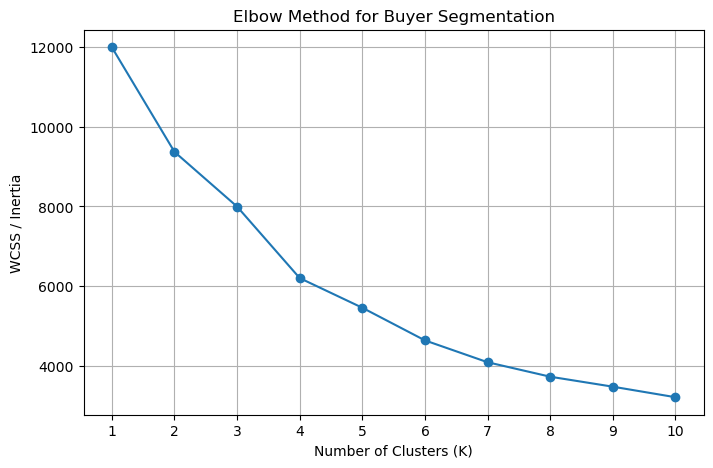

K = 1: WCSS = 12000.00
K = 2: WCSS = 9372.20
K = 3: WCSS = 7996.69
K = 4: WCSS = 6201.04
K = 5: WCSS = 5455.64
K = 6: WCSS = 4636.04
K = 7: WCSS = 4087.49
K = 8: WCSS = 3724.02
K = 9: WCSS = 3473.53
K = 10: WCSS = 3208.87


In [98]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Test different numbers of clusters
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(features_scaled_df)
    wcss.append(kmeans.inertia_)

# Plot the Elbow curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")

plt.title("Elbow Method for Buyer Segmentation")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

# Print the inertia values
for k, value in enumerate(wcss, start=1):
    print(f"K = {k}: WCSS = {value:.2f}")

In [99]:
# Check the variables currently available
%whos

Variable                    Type              Data/Info
-------------------------------------------------------
KMeans                      ABCMeta           <class 'sklearn.cluster._kmeans.KMeans'>
Path                        type              <class 'pathlib.Path'>
StandardScaler              type              <class 'sklearn.preproces<...>ng._data.StandardScaler'>
age_dmy                     Series            Shape: (2000,)
age_mdy                     Series            Shape: (2000,)
birth_dates                 Series            Shape: (2000,)
buyer_features              DataFrame         Shape: (2000, 5)
buyer_profile               DataFrame         Shape: (2000, 9)
buyer_property_df           DataFrame         Shape: (7305, 25)
buyer_segmentation_df       DataFrame         Shape: (2000, 13)
calculate_age               function          <function calculate_age at 0x7f6315f21bc0>
categorical_features        list              n=3
client_categorical_cols     list              n=7
clie

In [100]:
%whos

Variable                    Type              Data/Info
-------------------------------------------------------
KMeans                      ABCMeta           <class 'sklearn.cluster._kmeans.KMeans'>
Path                        type              <class 'pathlib.Path'>
StandardScaler              type              <class 'sklearn.preproces<...>ng._data.StandardScaler'>
age_dmy                     Series            Shape: (2000,)
age_mdy                     Series            Shape: (2000,)
birth_dates                 Series            Shape: (2000,)
buyer_features              DataFrame         Shape: (2000, 5)
buyer_profile               DataFrame         Shape: (2000, 9)
buyer_property_df           DataFrame         Shape: (7305, 25)
buyer_segmentation_df       DataFrame         Shape: (2000, 13)
calculate_age               function          <function calculate_age at 0x7f6315f21bc0>
categorical_features        list              n=3
client_categorical_cols     list              n=7
clie

In [101]:
from sklearn.cluster import KMeans

# Create K-Means model with 4 clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Fit model using the scaled features
cluster_labels = kmeans.fit_predict(features_scaled_df)

# Add cluster labels to your buyer dataset
buyer_segmentation_df["cluster"] = cluster_labels

# Display buyer counts in each cluster
print("Buyers in Each Cluster:")
print(buyer_segmentation_df["cluster"].value_counts().sort_index())

# View the updated dataset
buyer_segmentation_df.head()

Buyers in Each Cluster:
cluster
0    883
1    552
2    103
3    462
Name: count, dtype: int64


,client_ref,properties_purchased,total_purchase_value,avg_purchase_price,avg_floor_area,client_type,gender,country,region,acquisition_purpose,satisfaction_score,loan_applied,referral_channel,cluster
0,C0001,4,1246764.72,311691.18,983.885000,Individual,F,USA,California,Home,4,Yes,Website,0
1,C0002,5,1841095.93,368219.186,1187.942000,Individual,M,USA,California,Home,1,No,Website,0
2,C0003,5,1661457.59,332291.518,1058.110000,Individual,M,USA,California,Home,4,Yes,Agency,0
3,C0004,6,1608263.51,268043.918333,937.103333,Individual,M,USA,California,Home,5,No,Website,0
4,C0005,13,3653385.38,281029.644615,927.296154,Company,M,USA,California,Investment,5,No,Website,2


In [102]:
# Select numeric features for cluster profiling
profile_numeric = [
    "properties_purchased",
    "total_purchase_value",
    "avg_purchase_price",
    "avg_floor_area",
    "satisfaction_score"
]

# Calculate average values for each cluster
cluster_profile = (
    buyer_segmentation_df
    .groupby("cluster")[profile_numeric]
    .mean()
    .round(2)
)

print("Numeric Profile of Buyer Clusters:")
display(cluster_profile)

Numeric Profile of Buyer Clusters:


,properties_purchased,total_purchase_value,avg_purchase_price,avg_floor_area,satisfaction_score
cluster,,,,,
0,3.77,1171264.9,309682.84,1029.27,3.04
1,3.42,1470311.47,431163.23,1413.79,3.04
2,3.70,1263753.49,344854.97,1142.98,3.07
3,3.69,1179102.84,318631.6,1056.22,2.98


In [103]:
# Compare categorical characteristics across clusters
categorical_features = [
    "acquisition_purpose",
    "client_type",
    "loan_applied"
]

for col in categorical_features:
    print(f"\n{col.replace('_', ' ').title()} — Percentage within each cluster:")

    cluster_percentages = pd.crosstab(
        buyer_segmentation_df["cluster"],
        buyer_segmentation_df[col],
        normalize="index"
    ).mul(100).round(1)

    display(cluster_percentages)


Acquisition Purpose — Percentage within each cluster:


acquisition_purpose,Home,Investment
cluster,,
0,100.0,0.0
1,78.8,21.2
2,65.0,35.0
3,0.0,100.0



Client Type — Percentage within each cluster:


client_type,Company,Individual
cluster,,
0,0.0,100.0
1,0.0,100.0
2,100.0,0.0
3,0.0,100.0



Loan Applied — Percentage within each cluster:


loan_applied,No,Yes
cluster,,
0,63.6,36.4
1,64.3,35.7
2,58.3,41.7
3,62.1,37.9


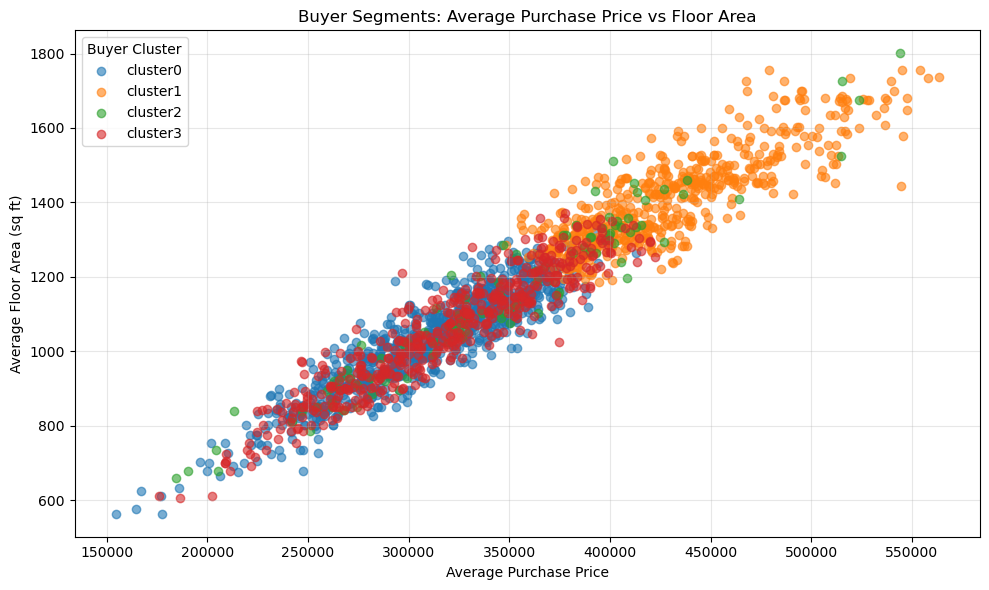

In [104]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
for cluster in sorted(buyer_segmentation_df["cluster"].unique()):
    cluster_data = buyer_segmentation_df[
        buyer_segmentation_df["cluster"] == cluster
        ]
    plt.scatter(
    cluster_data["avg_purchase_price"],
    cluster_data["avg_floor_area"],
    label=f"cluster{cluster}",
    alpha=0.6
    )
    plt.title("Buyer Segments: Average Purchase Price vs Floor Area")
plt.xlabel("Average Purchase Price")
plt.ylabel("Average Floor Area (sq ft)")
plt.legend(title="Buyer Cluster")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [105]:
from sklearn.metrics import silhouette_score

# Calculate the silhouette score using the scaled features
sil_score = silhouette_score(
    features_scaled_df,
    buyer_segmentation_df["cluster"]
)

print(f"Silhouette Score: {sil_score:.3f}")

Silhouette Score: 0.281


In [106]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_results = {}

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(features_scaled_df)

    score = silhouette_score(
        features_scaled_df,
        labels
    )

    silhouette_results[k] = score

print("Silhouette Scores:")
for k, score in silhouette_results.items():
    print(f"K = {k}: {score:.3f}")

Silhouette Scores:
K = 2: 0.224
K = 3: 0.247
K = 4: 0.281
K = 5: 0.259
K = 6: 0.274
K = 7: 0.289
K = 8: 0.277


In [107]:
# Fit a new K-Means model with 7 clusters
kmeans_7 = KMeans(
    n_clusters=7,
    random_state=42,
    n_init=10
)

# Assign seven-cluster labels
labels_7 = kmeans_7.fit_predict(features_scaled_df)

# Save labels separately for comparison
buyer_segmentation_df["cluster_7"] = labels_7

# Display buyer counts
print("Buyer Counts for K = 7:")

display(
    buyer_segmentation_df["cluster_7"]
    .value_counts()
    .sort_index()
)

Buyer Counts for K = 7:


cluster_7
0    399
1    326
2    496
3    392
4    237
5    102
6     48
Name: count, dtype: int64

In [108]:
# Numeric profile for the 7-cluster solution
numeric_cols = [
    "properties_purchased",
    "total_purchase_value",
    "avg_purchase_price",
    "avg_floor_area",
    "satisfaction_score"
]

profile_7 = (
    buyer_segmentation_df
    .groupby("cluster_7")[numeric_cols]
    .mean()
    .round(2)
)

print("Numeric Buyer Profiles — K = 7")
display(profile_7)


# Categorical profile: percentages within each cluster
for col in ["acquisition_purpose", "client_type"]:
    print(f"\n{col} — Percentage within each cluster:")

    display(
        pd.crosstab(
            buyer_segmentation_df["cluster_7"],
            buyer_segmentation_df[col],
            normalize="index"
        ).mul(100).round(1)
    )

Numeric Buyer Profiles — K = 7


,properties_purchased,total_purchase_value,avg_purchase_price,avg_floor_area,satisfaction_score
cluster_7,,,,,
0,3.44,1478320.34,431199.1,1416.35,2.81
1,3.56,1055098.88,296773.69,985.59,2.90
2,3.70,1186392.92,320824.55,1065.44,4.21
3,3.56,1072649.55,301399.41,1002.73,1.71
4,3.47,1420361.42,410221.86,1343.78,3.17
5,3.61,1240325.73,345480.71,1145.10,3.05
6,7.38,2393135.81,325918.58,1077.65,3.54



acquisition_purpose — Percentage within each cluster:


acquisition_purpose,Home,Investment
cluster_7,,
0,100.0,0.0
1,0.0,100.0
2,100.0,0.0
3,100.0,0.0
4,0.0,100.0
5,65.7,34.3
6,64.6,35.4



client_type — Percentage within each cluster:


client_type,Company,Individual
cluster_7,,
0,0.0,100.0
1,0.0,100.0
2,0.0,100.0
3,0.0,100.0
4,0.0,100.0
5,100.0,0.0
6,2.1,97.9


In [109]:
# Investigate buyers assigned to Cluster 6
cluster_6 = buyer_segmentation_df[
    buyer_segmentation_df["cluster_7"] == 6
]

print("Cluster 6 — Properties Purchased:")
display(
    cluster_6["properties_purchased"].describe().round(2)
)

print("\nHighest property counts in Cluster 6:")
display(
    cluster_6[
        ["client_ref", "properties_purchased",
         "total_purchase_value", "avg_purchase_price",
         "acquisition_purpose", "client_type"]
    ]
    .sort_values("properties_purchased", ascending=False)
    .head(10)
)

Cluster 6 — Properties Purchased:


count    48.00
mean      7.38
std       1.39
min       6.00
25%       6.00
50%       7.00
75%       8.00
max      13.00
Name: properties_purchased, dtype: float64


Highest property counts in Cluster 6:


,client_ref,properties_purchased,total_purchase_value,avg_purchase_price,acquisition_purpose,client_type
4,C0005,13,3653385.38,281029.644615,Investment,Company
6,C0007,11,3251147.83,295558.893636,Investment,Individual
25,C0026,10,2932241.75,293224.175,Investment,Individual
49,C0050,9,2744452.35,304939.15,Home,Individual
160,C0161,9,2534264.26,281584.917778,Home,Individual
101,C0102,9,3403263.85,378140.427778,Investment,Individual
91,C0092,8,2817926.96,352240.87,Home,Individual
45,C0046,8,2026517.4,253314.675,Home,Individual
172,C0173,8,2619968.43,327496.05375,Home,Individual
178,C0179,8,2131372.11,266421.51375,Investment,Individual


In [110]:
segment_summary = (
    buyer_segmentation_df
    .groupby("cluster_7")
    .agg(
        buyer_count=("client_ref", "count"),
        avg_properties=("properties_purchased", "mean"),
        avg_total_purchase_value=("total_purchase_value", "mean"),
        avg_purchase_price=("avg_purchase_price", "mean"),
        avg_floor_area=("avg_floor_area", "mean"),
        avg_satisfaction=("satisfaction_score", "mean")
    )
    .round(2)
)

segment_summary["buyer_percentage"] = (
    segment_summary["buyer_count"] / len(buyer_segmentation_df) * 100
).round(2)

segment_summary 

,buyer_count,avg_properties,avg_total_purchase_value,avg_purchase_price,avg_floor_area,avg_satisfaction,buyer_percentage
cluster_7,,,,,,,
0,399,3.44,1478320.34,431199.1,1416.35,2.81,19.95
1,326,3.56,1055098.88,296773.69,985.59,2.90,16.30
2,496,3.70,1186392.92,320824.55,1065.44,4.21,24.80
3,392,3.56,1072649.55,301399.41,1002.73,1.71,19.60
4,237,3.47,1420361.42,410221.86,1343.78,3.17,11.85
5,102,3.61,1240325.73,345480.71,1145.10,3.05,5.10
6,48,7.38,2393135.81,325918.58,1077.65,3.54,2.40


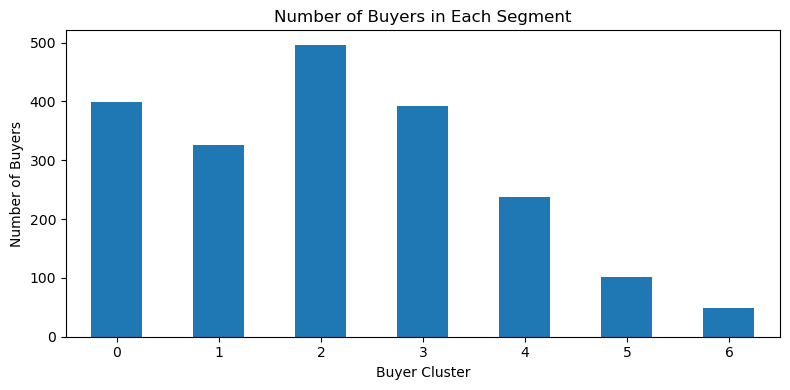

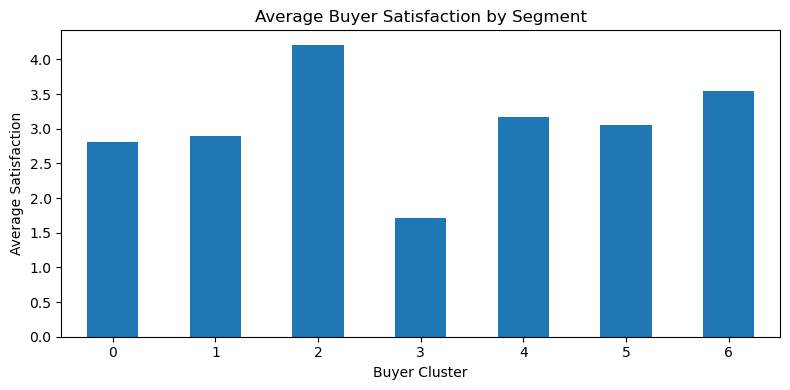

In [111]:
import matplotlib.pyplot as plt

# Chart 1: Number of buyers in each cluster
segment_summary["buyer_count"].plot(
    kind="bar",
    figsize=(8, 4),
    title="Number of Buyers in Each Segment"
)

plt.xlabel("Buyer Cluster")
plt.ylabel("Number of Buyers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# Chart 2: Average satisfaction by cluster
segment_summary["avg_satisfaction"].plot(
    kind="bar",
    figsize=(8, 4),
    title="Average Buyer Satisfaction by Segment"
)

plt.xlabel("Buyer Cluster")
plt.ylabel("Average Satisfaction")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [112]:
# Acquisition purpose within each cluster
print(pd.crosstab(
    buyer_segmentation_df["cluster_7"],
    buyer_segmentation_df["acquisition_purpose"],
    normalize="index"
).mul(100).round(1))

# Client type within each cluster
print(pd.crosstab(
    buyer_segmentation_df["cluster_7"],
    buyer_segmentation_df["client_type"],
    normalize="index"
).mul(100).round(1))

acquisition_purpose   Home  Investment
cluster_7                             
0                    100.0         0.0
1                      0.0       100.0
2                    100.0         0.0
3                    100.0         0.0
4                      0.0       100.0
5                     65.7        34.3
6                     64.6        35.4
client_type  Company  Individual
cluster_7                       
0                0.0       100.0
1                0.0       100.0
2                0.0       100.0
3                0.0       100.0
4                0.0       100.0
5              100.0         0.0
6                2.1        97.9


In [113]:
segment_names = {
    0: "Premium Home Buyers",
    1: "Individual Investment Buyers",
    2: "Satisfied Home Buyers",
    3: "Low-Satisfaction Home Buyers",
    4: "Larger-Property Investors",
    5: "Corporate Property Buyers",
    6: "High-Frequency Individual Buyers"
}

buyer_segmentation_df["segment_name"] = (
    buyer_segmentation_df["cluster_7"].map(segment_names)
)

buyer_segmentation_df[
    ["client_ref", "cluster_7", "segment_name"]
].head()

,client_ref,cluster_7,segment_name
0,C0001,2,Satisfied Home Buyers
1,C0002,3,Low-Satisfaction Home Buyers
2,C0003,2,Satisfied Home Buyers
3,C0004,6,High-Frequency Individual Buyers
4,C0005,6,High-Frequency Individual Buyers


In [114]:
final_segment_summary = segment_summary.copy()

final_segment_summary["segment_name"] = (
    final_segment_summary.index.map(segment_names)
)

final_segment_summary = final_segment_summary.reset_index()

final_segment_summary

,cluster_7,buyer_count,avg_properties,avg_total_purchase_value,avg_purchase_price,avg_floor_area,avg_satisfaction,buyer_percentage,segment_name
0,0,399,3.44,1478320.34,431199.1,1416.35,2.81,19.95,Premium Home Buyers
1,1,326,3.56,1055098.88,296773.69,985.59,2.90,16.30,Individual Investment Buyers
2,2,496,3.70,1186392.92,320824.55,1065.44,4.21,24.80,Satisfied Home Buyers
3,3,392,3.56,1072649.55,301399.41,1002.73,1.71,19.60,Low-Satisfaction Home Buyers
4,4,237,3.47,1420361.42,410221.86,1343.78,3.17,11.85,Larger-Property Investors
5,5,102,3.61,1240325.73,345480.71,1145.10,3.05,5.10,Corporate Property Buyers
6,6,48,7.38,2393135.81,325918.58,1077.65,3.54,2.40,High-Frequency Individual Buyers


In [115]:
# Verify buyer segmentation
print("Total buyer records:", len(buyer_segmentation_df))

print("\nMissing segment names:")
print(buyer_segmentation_df["segment_name"].isna().sum())

print("\nBuyer count by segment:")
print(buyer_segmentation_df["segment_name"].value_counts())

# Save buyer-level segmentation
buyer_segmentation_df.to_csv(
    "real_estate_buyer_segments.csv",
    index=False
)

# Save segment summary
final_segment_summary.to_csv(
    "real_estate_segment_summary.csv",
    index=False
)

print("\nBoth CSV files saved successfully.")

Total buyer records: 2000

Missing segment names:
0

Buyer count by segment:
segment_name
Satisfied Home Buyers               496
Premium Home Buyers                 399
Low-Satisfaction Home Buyers        392
Individual Investment Buyers        326
Larger-Property Investors           237
Corporate Property Buyers           102
High-Frequency Individual Buyers     48
Name: count, dtype: int64

Both CSV files saved successfully.
